In [2]:
from IPython.display import Audio
import numpy as np
import matplotlib.pyplot as plt

In [3]:
freq_Do = Freq_Do = 262
Fs_global = 22050
Init_duration = 1
N_global = int(Fs_global * Init_duration)
T_global = np.linspace(0, Init_duration, N_global, endpoint=False) 
Amplitude_global = 0.5

# με endpoint False, το τελευταίο σημείο δεν περιλαμβάνεται στο διάστημα, δηλαδή η τιμή του T_global θα είναι από 0 έως 2 δευτερόλεπτα, αλλά δεν θα περιλαμβάνει το 2.
# το βημα ειναι 2/N_global = 2/22050 = 0.0000907 δευτερόλεπτα, δηλαδή περίπου 90.7 μικροδευτερόλεπτα.
# με endpoint True, το βημα ειναι 2/(N_global-1) = 2/22049 = 0.0000907 δευτερόλεπτα, δηλαδή περίπου 90.7 μικροδευτερόλεπτα.


In [4]:
Do_sinewave =Amplitude_global * np.sin(2 * np.pi * freq_Do * T_global)


In [5]:
Do = Audio(Do_sinewave, rate=Fs_global, autoplay= False)
display(Do)


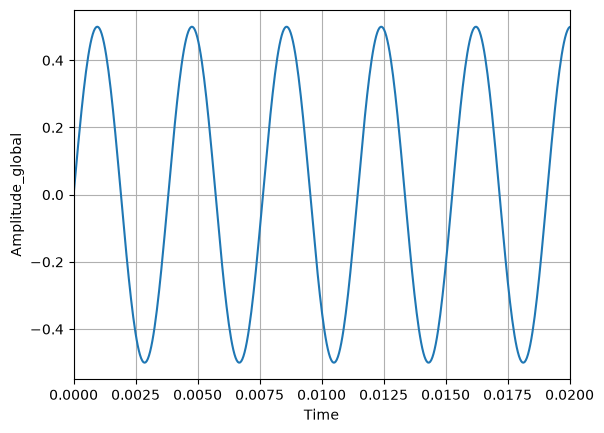

In [6]:
plt.plot(T_global, Do_sinewave)
plt.xlim(0, 0.02)  # περιορισμός του άξονα x για να φανούν οι πρώτες 100 χιλιοστά του δευτερολέπτου
plt.xlabel('Time')
plt.ylabel("Amplitude_global")
plt.grid()
plt.show()

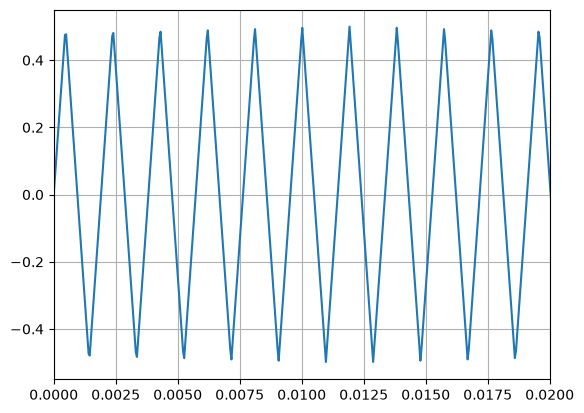

In [7]:
Do_triangle = Amplitude_global * (2/np.pi) * np.arcsin(
    np.sin(4 * np.pi * freq_Do * T_global)
)

plt.plot(T_global, Do_triangle)
plt.xlim(0, 0.02) 
plt.grid()
plt.show()

Audio(Do_triangle, rate=Fs_global, autoplay= False)

In [8]:
# συναρτησεις στην python 
# γενικος τυπος

#   def function_name(parameters):
#       # function body
#       return result


In [9]:
A = [1,2,3,4,5]
B = [10,20,30,40,50]
list(zip(A,B))

[(1, 10), (2, 20), (3, 30), (4, 40), (5, 50)]

In [10]:
Gain_sine = 0.5
Gain_triangle = 0.5

In [11]:
def add_signal(signal_sine, signal_triangle, Gain_sine=1, Gain_triangle=0.05):
    result = []
    for a, b in zip(signal_sine, signal_triangle):
        result.append(Gain_sine * a + Gain_triangle * b) 
    return result

In [12]:
c = add_signal(A, B)
print(c)  

[1.5, 3.0, 4.5, 6.0, 7.5]


In [13]:
Do_mix = add_signal(Do_sinewave, Do_triangle)
Wave_Do = Audio(Do_mix, rate=Fs_global, autoplay= False)
display(Wave_Do)


In [14]:
Freq_Do = 262
n_semitone = 0
Freq_Do_Scale = Freq_Do +  (2 ** (n_semitone / 12))

print(Freq_Do_Scale)  # Εκτυπώνει τη συχνότητα του ντο στην κλίμακα με βάση τον αριθμό των ημιτονίων

263.0


In [15]:
Notes = ["Do", "Do#", "Re", "Re#", "Mi", "Fa", "Fa#", "Sol", "Sol#", "La", "La#", "Si"]

for i in range(len(Notes)):
    Freq_Note = Freq_Do * (2 ** (i / 12))
    print(Notes[i], ":", Freq_Note, "Hz")

Do : 262.0 Hz
Do# : 277.57933072213535 Hz
Re : 294.0850566570557 Hz
Re# : 311.5722641307129 Hz
Mi : 330.09931507245676 Hz
Fa : 349.728041792549 Hz
Fa# : 370.52395334175094 Hz
Sol : 392.55645414169055 Hz
Sol# : 415.8990756156682 Hz
La : 440.6297215929464 Hz
La# : 466.8309283055378 Hz
Si : 494.5901398452074 Hz


In [16]:
note_name = "Re#"
n = Notes.index(note_name)
print(n)

# μεσα στην λιστα Notes, βρες το "Re#" και δωσε μου την θεση του
# η θεση ειναι n, η ρε# ειναι στην θεση 3, δηλαδη Notes[3] = "Re#"



3


In [17]:
def play_note(note_name, octave, duration=1):
    n = Notes.index(note_name)

    Freq_Note = Freq_Do * (2 ** (octave - 4 + n / 12))

    N = int(Fs_global * duration)
    T = np.linspace(0, duration, N, endpoint=False)

    Sine = Amplitude_global * np.sin(2 * np.pi * Freq_Note * T)
    Triangle = Amplitude_global * (2/np.pi) * np.arcsin(
        np.sin(4 * np.pi * Freq_Note * T))

    Note_signal = add_signal(Sine, Triangle)
    return Note_signal

In [18]:
Note_signal = play_note("Fa#",3)

display(Audio(Note_signal, rate=Fs_global, autoplay=False))

In [19]:
def play(note_name, octave, duration=1):
    signal = play_note(note_name, octave, duration)
    display(Audio(signal, rate=Fs_global, autoplay=False))

In [20]:
play("Sol#",3)

In [21]:
def Melody(*notes):
    signals = []

    for note in notes:
        if len(note) == 2:
            signals.append(play_note(note[0], note[1]))
        else:
            signals.append(play_note(note[0], note[1], note[2]))

    Melody_signal = np.concatenate(signals)
    display(Audio(Melody_signal, rate=Fs_global, autoplay=False))

In [22]:
Melody(("Do", 4, 0.2), ("Mi", 4, 0.2), ("Sol", 4, 0.2))

In [23]:
Note_Dictionary = {
    "C": "Do",
    "C#": "Do#",
    "D": "Re",
    "D#": "Re#",
    "E": "Mi",
    "F": "Fa",
    "F#": "Fa#",
    "G": "Sol",
    "G#": "Sol#",
    "A": "La",
    "A#": "La#",
    "B": "Si"
}

Chord_Types = {
    "": [0, 4, 7],
    "m": [0, 3, 7],
    "dim": [0, 3, 6],
    "aug": [0, 4, 8],
    "7": [0, 4, 7, 10],
    "maj7": [0, 4, 7, 11],
    "m7": [0, 3, 7, 10],
    "m7b5": [0, 3, 6, 10],
    "dim7": [0, 3, 6, 9],
    "mmaj7": [0, 3, 7, 11]
}


In [24]:
def Chord(chord_name):
    # chord name ειναι η παραμετρος που δεχεται για εισοδο.
    # chord_name[0] ειναι πχ το C
    # chord_name[1] ειναι πχ το # ή το m ή το 7 κλπ
    # chord_name[2:] ειναι πχ το maj7 ή το m7b5 κλπ
    if len(chord_name) > 1 and chord_name[1] == "#":
        root_name = chord_name[:2]
        chord_ID = chord_name[2:]

        # αν το μηκος του chord_name >1 και ο δευτερος χαρακτηρας ειναι # τοτε 
        # τοτε η τονικη ειναι ειναι οι δυο πρωτοι χαρακτηρες
        # και ο τυπος του ειναι οι υπολοιποι χαρακτηρες πx maj7 
    else:
        root_name = chord_name[0]
        chord_ID = chord_name[1:]

        # αλλιως η τονικη ειναι ο πρωτος χαρακτηρας
        # και ο τυπος του ειναι οι υπολοιποι χαρακτηρες πx maj7

    root_note = Note_Dictionary[root_name]
    # ψαχνει την τονικη στο dictionary και την αντιστοιχιζει στην μεταβλητη root_note
    root_index = Notes.index(root_note)
    # μας επιστρεφει την αποσταση της νοτας απο την Do.

    intervals = Chord_Types[chord_ID]
    # βρες το στοιχειο μεσα Chord_types το που αντιστοιχει στο chord_ID
    # και απο αποθηκευσε το στην μεταβλητη intervals
    # αρα αν του πω Chord("Cmaj7") το chord_ID ειναι maj7 και intervals = [0, 4, 7, 11]
    chord_indices = [(root_index + interval) % 12 for interval in intervals]

    # for interval in intervals: για καθε interval μεσα στο intervals
    # πχ εχω intervals = [0, 4, 7, 11] 

    ## root_index = 0 εχω 0 + 0 = 0
    ## root_index = 0 εχω 0 + 4 = 4 
    ## root_index = 0 εχω 0 + 7 = 7
    ## root_index = 0 εχω 0 + 11 = 11
    
    ### και καθενα καντο mod 12 για να μην ξεπερναει το 12
    ### το mod 12 μας δινει το υπολοιπο της διαιρεσης με το 12, 
    ### δηλαδη αν εχω 13 mod 12 = 1, αν εχω 14 mod 12 = 2 κλπ

    #### νεα λιστα chord_indices = [0, 4, 7, 11] για το Cmaj7


    chord_notes = [Notes[i] for i in chord_indices]
    # εδω κανω το αντιστροφο. Μετατρεπω τους αριθμους σε ονοματα νοτων. 
    # πχ εχω [7, 11, 2]. i = 7 αρα Notes[7] = Sol 
    ## i = 11 αρα Notes[11] = Si , i = 2 αρα Notes[2] = Re 
    ### δημιουργεί την λιστα chord_notes = ["Sol", "Si", "Re"]

    return chord_notes

In [25]:
    # for interval in intervals: για καθε interval μεσα στο intervals
    # πχ εχω intervals της G, root index = 7, intervals = [0, 4, 7, 11] 

    ## root_index = 7 εχω 7 + 0 = 7
    ## root_index = 7 εχω 7 + 4 = 11 
    ## root_index = 7 εχω 7 + 7 = 14
    ## root_index = 7 εχω 7 + 11 = 18
    
    ### και καθενα καντο mod 12 για να μην ξεπερναει το 12
    ### το mod 12 μας δινει το υπολοιπο της διαιρεσης με το 12, 
    ### δηλαδη αν εχω 7 mod 12 = 7, αν εχω 11 mod 12 = 11 
    ### αν εχω 14 mod 12 = 2, αν εχω 18 mod 12 = 6.

    #### chord_indices της G = [7, 11, 2, 6] για το Gmaj7
    #### 7 = G, 11 = B, 2 = D, 6 = F#. αρα εχω την Gmaj7



In [26]:

Chord("Cmaj7")

['Do', 'Mi', 'Sol', 'Si']

In [27]:
def play_chord(chord_name, octave=4, duration=2, play=True):
    chord_notes = Chord(chord_name)
    
    # ψαχνω ψαχνω τις νοτες που αντιστοιχουν στο chord_name 
    # και τις αποθηκευω στην μεταβλητη chord_notes
    # play=True: εμφανίζει τον ήχο της συγκεκριμένης συγχορδίας.
    # play=False: δεν εμφανίζει ξεχωριστό player, αλλά επιστρέφει το ηχητικό σήμα.

    signals = []

    # δημιουργω αδεια λιστα για να αποθηκευσω τα ηχητικα σηματα των νοτων.


    for note in chord_notes:

        # παρε μια μια τις νοτες στο chord_notes και εκτελεσε:

        signal = play_note(note, octave, duration)
        signals.append(signal)

        # η signal δημιουργει καθε φορα το ηχητικο κυμα της νοτας 
        # και το αποθηκευει στην λιστα signal.
        ## η signals.append() τα αποθηκευει ενα ενα στην λιστα signals.
        ## στο τελος θα εχω 	[Sol_signal, La#_signal, Re_signal]

    Chord_signal = np.sum(signals, axis=0)

    # το np.sum συνδυαζει τα σηματα
    ## το axis=0 προσθετει τα αντιστοιχα στοιχεια των λιστων,
    ## δλδ προσθετει τους ηχους στοιχειο προς στοιχειο. 


    if play:
        display(Audio(Chord_signal, rate=Fs_global, autoplay=False))

    # δεν εχω return γτ δεν θελω να επιστρεφει κατι,
    # απλα θελω να παιζει το ηχο του chord

    return Chord_signal 

    # τωρα το θελω.

In [28]:
play_chord('Gm') # εμφανιζει τον ηχο
signal = play_chord('Gm', play=False) # Επιστρεφει το σημα

In [29]:
play_chord("Gmaj7")

array([0.        , 0.23466593, 0.46636094, ..., 0.92329892, 1.10880309,
       1.27587946], shape=(44100,))

In [30]:
def Chord_progression(chords_names, octave=4, duration=1):
    list_progression = []

    for chord_name in chords_names:
        signal_progression = play_chord(
            chord_name, octave=octave, duration=duration, play=False
        )
        list_progression.append(signal_progression)

    Progression = np.concatenate(list_progression)

    display(Audio(Progression, rate=Fs_global, autoplay=False))

    return Progression


In [31]:
Chord_progression(["Dm7", "G7", "Cmaj7"])

array([ 0.        ,  0.20371728,  0.40545364, ..., -0.01561776,
       -0.04657039, -0.07537593], shape=(66150,))

In [32]:
Chord_progression(["Cmaj7", "D", "Em7",])

array([0.        , 0.22372043, 0.44472753, ..., 0.25120418, 0.22356666,
       0.19640327], shape=(66150,))

In [33]:
Chord_progression([
    "Gm7", "C7", "Fmaj7", "A#maj7",
    "Em7b5", "A7", "Dm"
])

array([ 0.        ,  0.22736024,  0.45206373, ..., -0.48876482,
       -0.51940211, -0.54240818], shape=(154350,))

In [34]:
play_chord("A#maj7")

array([0.        , 0.2345973 , 0.46624968, ..., 0.85739982, 0.80669819,
       0.74300106], shape=(44100,))

In [35]:
for note in Chord("A#maj7"):
    n = Notes.index(note)
    freq = Freq_Do * (2 ** (n / 12))
    print(note, freq)

La# 466.8309283055378
Re 294.0850566570557
Fa 349.728041792549
La 440.6297215929464


In [36]:
%pip install numba

Note: you may need to restart the kernel to use updated packages.


In [45]:
play_chord( "C7")

array([0.        , 0.21955068, 0.43660899, ..., 0.23684287, 0.30490436,
       0.36636051], shape=(44100,))